# Cell line and tumor-subpopulation GSEA and MLM concordance

This notebook covers two complementary views of the same question: does the
matched tumor subpopulation also have a similar pathway profile to the cell
line?

1. **GSEA concordance**: direct cell line versus subpopulation DE and
   Hallmark GSEA, followed by a cell line signature correlated with each
   subpopulation signature.
2. **MLM concordance**: per-cell Hallmark MLM scores, domain shift, MLM
   pathway correlation, MLM/GSEA direction agreement, and tumor-centered or
   z-scored pathway similarity.

The latent candidate table is the matching result. All views are
descriptive: they use the same expression data and largely overlapping
Hallmark programs, so they support a candidate but do not independently
validate it. The final summary table combines the GSEA signature rank and
the MLM primary-minus-runner-up difference.

In [1]:
from pathlib import Path
import sys

import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.bio import matching, mlm, plots, signatures
from src.utils import load_config

cfg = load_config()
paths = cfg["paths"]
bio = cfg.get("bio", {})
FIG_DIR = ROOT / paths["bio"]["figures"]
FIG_DIR.mkdir(parents=True, exist_ok=True)

K_MATCHING = int(bio.get("matching", {}).get("k", 50))
MARGIN = float(bio.get("matching", {}).get("margin", 0.10))
GSEA = bio.get("gsea", {})
MLM = bio.get("mlm", {})
SEED = 0
FORCE_RECOMPUTE = False

# Inputs and matching groups

The model and cache directories follow the frozen artifact settings. The
candidate table is recomputed with the shared matching function so this
notebook and `2_candidate_matching.ipynb` stay aligned.

For this run, `de_dir` is
`models/validation/bio_joint_cfg10/de_signatures`. All DE/GSEA/MLM caches
below live there unless stated otherwise.

In [2]:
combined = ad.read_h5ad(ROOT / paths["bio"]["joint_artifact"])
settings = combined.uns["bio_leiden_settings"]
approach = settings["approach"]
config_id = int(settings["config_id"])
num_hvg = int(settings["num_hvg"])
tumor_res = float(settings["tumor_res"])
tumor_key = f"tumor_leiden_res{tumor_res}"

de_dir = ROOT / paths["bio"]["de_joint"]
line_vs_tumor_dir = de_dir / "line_vs_tumor"
gsea_dir = de_dir / "gsea_hallmark"
gmt_path = ROOT / paths["bio"]["hallmark_gmt"]
line_vs_tumor_dir.mkdir(parents=True, exist_ok=True)

group = matching.make_match_groups(combined.obs, tumor_key)
combined.obs["match_group"] = group

composition, line_matches, baseline, tumor_order = matching.match_lines(
    combined.obsm["X_latent"], group, combined.obs, K_MATCHING, margin=MARGIN
)
line_order = matching.line_order(line_matches)
line_matches = line_matches.loc[line_order]

run_dir = ROOT / paths["hpo"]["runs"] / f"hvg{num_hvg}" / f"config_{config_id:02d}" / approach
model_dir = run_dir / ("joint_scanvi" if approach == "joint" else "query")

groups_de = combined.obs["match_group"].astype(str).to_numpy()
line_mask_de = combined.obs["dataset"].eq("cell_line").to_numpy()
line_groups = sorted(pd.unique(groups_de[line_mask_de]))
tumor_subpops = tumor_order

print(f"model: {model_dir.relative_to(ROOT)}")
print(f"{len(line_groups)} cell lines x {len(tumor_subpops)} tumor subpopulations")

model: models/hpo/runs/hvg3000/config_10/joint/joint_scanvi
10 cell lines x 18 tumor subpopulations


# GSEA concordance

## Direct cell line versus subpopulation DE and GSEA

`lfc_mean > 0` means higher expression in the cell line than in the tumor
subpopulation. The DE is the model-based scANVI differential expression with
`batch_correction=True`. GSEA uses the full signed `lfc_mean` ranking.
The 10 lines × 18 subpopulations give 180 DE contrasts,
cached under `de_dir/line_vs_tumor/`. The combined GSEA table is
`de_dir/line_vs_tumor/hallmark_prerank_line_vs_tumor.csv`.

In [3]:
line_de, line_rankings, qc = signatures.load_or_run_line_vs_tumor_de(
    model_dir,
    combined,
    groups_de,
    line_groups,
    tumor_subpops,
    line_vs_tumor_dir,
    model_label=f"config_{config_id:02d}_{approach}",
    batch_correction=True,
    mode="change",
    delta=0.25,
    force=FORCE_RECOMPUTE,
)
qc.round(3).head()

,comparison,n_source,n_rest,n_genes,n_de_fdr_0.05,n_up_fdr_0.05,n_down_fdr_0.05,max_proba_de,median_abs_lfc,top_up,top_down
0,line_CCK81_vs_tumor_0,127,12126,3000,142,92,50,0.989,0.440,"BIRC5, UBE2C, PBK, PTTG1, CDKN3, RRM2, TOP2A, ...","C17orf78, NDUFA4L2, CLIC3, BCAS1, NDRG1, CA7, ..."
1,line_CCK81_vs_tumor_1,127,10323,3000,121,77,44,0.988,0.575,"PTTG1, BIRC5, UBE2C, PBK, CDKN3, CCNA2, RRM2, ...","PLA2G4C, F10, MMP7, RP11-21B23.3, HPN, GABARAP..."
2,line_CCK81_vs_tumor_2,127,3276,3000,494,287,207,1.000,0.812,"GAL, UBE2C, PTTG1, BIRC5, CDKN3, NUF2, MAD2L1,...","CA1, PYY, UGT2B17, CA7, BEST4, MS4A12, SPIB, N..."
3,line_CCK81_vs_tumor_3,127,7047,3000,489,149,340,0.998,0.760,"PTTG1, CDKN3, PBK, BIRC5, MAD2L1, CCNB1, TOP2A...","EMP1, GAST, RSAD2, KRT16, KRT17, MMP7, DUSP5, ..."
4,line_CCK81_vs_tumor_4,127,11847,3000,0,0,0,0.915,0.298,"PTTG1, GP2, CCNB1, REG1A, LIPF, PTGDR, MT1A, C...","ATF3, DUSP5, EMP1, PSORS1C2, HBEGF, SEMA7A, KR..."


In [4]:
hallmark_sets = signatures.read_gmt(gmt_path)
results_gsea_line_vs_tumor = signatures.load_or_run_line_vs_tumor_gsea(
    line_rankings,
    line_vs_tumor_dir,
    gmt_path,
    hallmark_sets,
    seed=SEED,
    permutations=int(GSEA.get("permutations", 1000)),
    min_size=int(GSEA.get("min_size", 15)),
    max_size=int(GSEA.get("max_size", 500)),
    force=FORCE_RECOMPUTE,
)
print(f"{len(results_gsea_line_vs_tumor)} rows")
results_gsea_line_vs_tumor.head(3)

8100 rows


,cell_line,subpop,pathway,es,nes,nom_pval,fdr_qval,fwer_pval,tag_pct,gene_pct,overlap,set_size,lead_genes,comparison
0,CCK81,tumor_0,E2F_TARGETS,0.953910,3.505896,0.0,0.0,0.0,47/51,3.83%,51,200,BIRC5;PTTG1;CDKN3;RRM2;TOP2A;CDC20;MYBL2;CDK1;...,line_CCK81-vs-tumor_0
1,CCK81,tumor_0,G2M_CHECKPOINT,0.948748,3.392839,0.0,0.0,0.0,41/49,2.90%,49,200,BIRC5;UBE2C;PBK;PTTG1;CDKN3;TOP2A;CCNA2;CDC20;...,line_CCK81-vs-tumor_0
2,CCK81,tumor_0,MITOTIC_SPINDLE,0.816663,2.863297,0.0,0.0,0.0,23/44,4.23%,44,199,BIRC5;TOP2A;CDK1;NUSAP1;NEK2;PLK1;TPX2;DLGAP5;...,line_CCK81-vs-tumor_0


## Signature view

Each cell line's direct GSEA profile is averaged across subpopulations
into one line-level signature. That signature is correlated with each
subpopulation's vs-rest GSEA signature. The primary rank is the position
of the latent candidate in that correlation ranking.

This section reads the cached line-vs-tumor and tumor GSEA tables. The
readout and null table stay in memory.

The null table compares the observed median primary rank with a
random-rank baseline. It is a descriptive sanity check, not a biological
null and not a formal p-value.

In [5]:
results_gsea_tumor = pd.read_csv(gsea_dir / "hallmark_prerank_tumor.csv")
signature_order = [str(line).replace("line_", "") for line in line_order]
line_signature = (
    results_gsea_line_vs_tumor.groupby(["cell_line", "pathway"], observed=True)["nes"]
    .mean()
    .unstack("pathway")
    .loc[signature_order]
)
tumor_signature = results_gsea_tumor.pivot_table(
    index="pathway", columns="subpopulation", values="nes"
)
tumor_cols = [s for s in tumor_order if s in tumor_signature.columns]
tumor_signature = tumor_signature.loc[:, tumor_cols]

shared_proliferation = signatures.shared_proliferation_pathways(results_gsea_tumor)
print(f"Shared proliferation pathways ({len(shared_proliferation)}): {shared_proliferation}")

signature_all = signatures.signature_matrix(
    line_signature, tumor_signature, signature_order, tumor_cols
)
signature_noprolif = signatures.signature_matrix(
    line_signature,
    tumor_signature,
    signature_order,
    tumor_cols,
    exclude=shared_proliferation,
)
signature_sets = {
    "all Hallmark": signature_all,
    "excluding shared proliferation": signature_noprolif,
}

signature_readout, signature_null = signatures.signature_readout_and_null(
    signature_sets, line_matches, n_perm=1000, seed=SEED
)
display(signature_readout)
display(signature_null.round(3))

Shared proliferation pathways (4): ['E2F_TARGETS', 'G2M_CHECKPOINT', 'MITOTIC_SPINDLE', 'MYC_TARGETS_V1']


,cell_line,latent_primary,latent_runner_up,all Hallmark: best,all Hallmark: primary rank,all Hallmark: runner-up rank,excluding shared proliferation: best,excluding shared proliferation: primary rank,excluding shared proliferation: runner-up rank
0,HCC56,tumor_4,tumor_5,tumor_4,1,2,tumor_4,1,2
1,HT55,tumor_4,tumor_5,tumor_4,1,2,tumor_4,1,2
2,LS180,tumor_4,tumor_5,tumor_5,2,1,tumor_5,2,1
3,LS1034,tumor_4,tumor_3,tumor_4,1,8,tumor_4,1,7
4,CL34,tumor_4,tumor_5,tumor_4,1,2,tumor_4,1,2
5,RCM1,tumor_5,tumor_4,tumor_5,1,2,tumor_5,1,2
6,CCK81,tumor_5,tumor_4,tumor_5,1,3,tumor_5,1,3
7,NCIH747,tumor_5,tumor_4,tumor_5,1,2,tumor_5,1,2
8,SNUC4,tumor_5,tumor_4,tumor_4,2,1,tumor_4,2,1
9,OUMS23,tumor_6,tumor_5,tumor_6,1,18,tumor_6,1,16


,signature_set,median_primary_rank,null_median_rank,top1_rate,top3_rate,permutation_p
0,all Hallmark,1.0,9.5,0.8,1.0,0.0
1,excluding shared proliferation,1.0,9.5,0.8,1.0,0.0


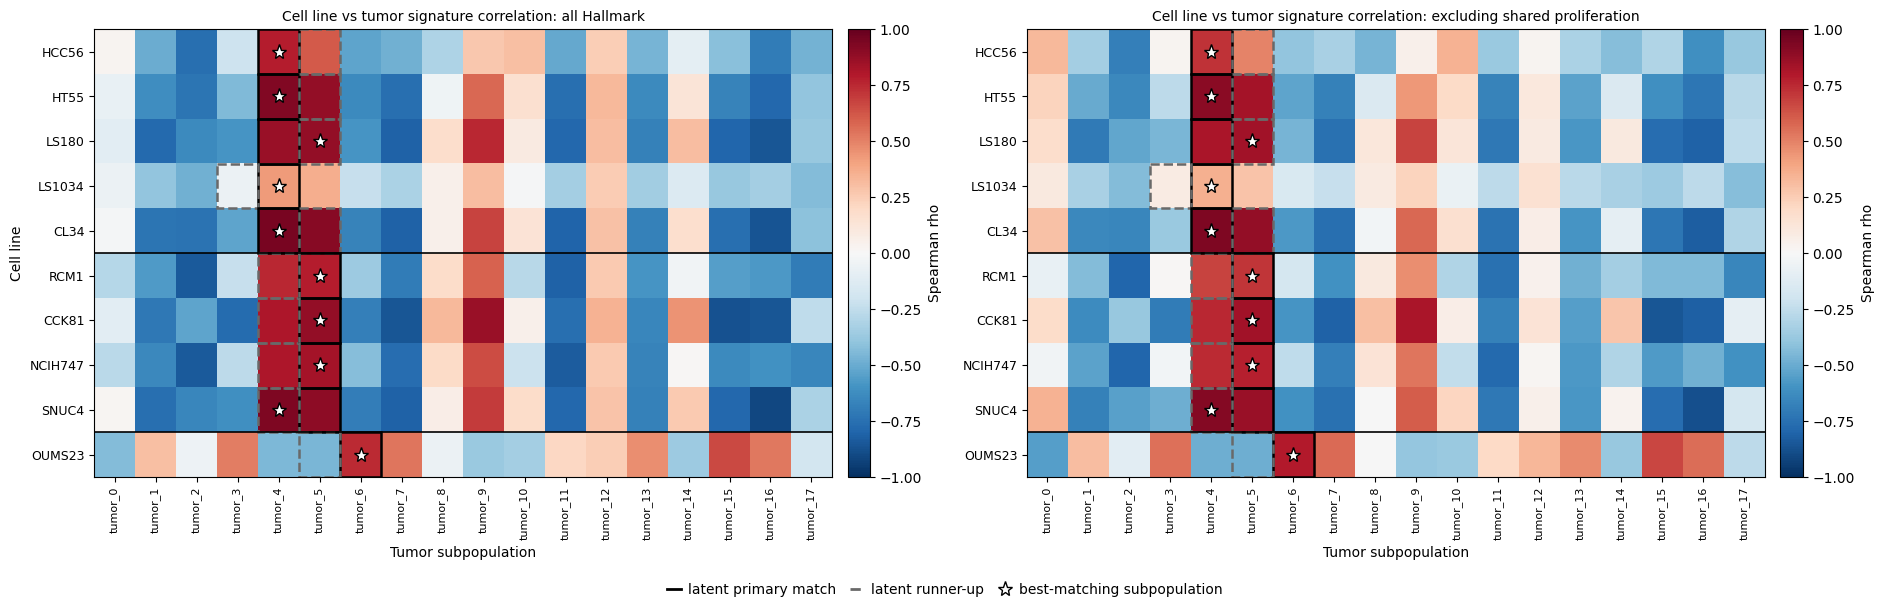

In [6]:
plots.plot_signature_match(
    signature_sets,
    line_matches,
    signature_order,
    tumor_cols,
    path=FIG_DIR / "cl_tumor_gsea_signature_match.png",
)
plt.show()

# MLM concordance

## Hallmark MLM scoring

The per-cell MLM scores use the full-gene, log-normalized, uncorrected `X`
subset to the Hallmark genes present in the artifact. This is independent
of the scANVI DE. The scores are computed once and then reloaded. The group summaries
below never pool tumor and cell line cells.

Scores are cached in `de_dir/hallmark_mlm/hallmark_mlm_scores.h5ad`.

In [7]:
mlm_dir = de_dir / "hallmark_mlm"
pathway_scores, score_obs, mlm_artifact, _ = mlm.load_or_score_primary_mlm(
    combined,
    hallmark_sets,
    mlm_dir,
    tmin=int(MLM.get("tmin", 15)),
    raw=bool(MLM.get("raw", False)),
    force=FORCE_RECOMPUTE,
)
print(f"{pathway_scores.shape[0]:,} cells x {pathway_scores.shape[1]} pathways")

110,293 cells x 50 pathways


## Domain shift

The cell line minus tumor median difference is descriptive. It shows
whether the two domains have broad pathway shifts before any
line/subpopulation comparison.

Saved to `de_dir/hallmark_mlm/domain_shift_all50.csv`.

In [8]:
domain_shift = mlm.domain_shift(pathway_scores, score_obs)
domain_shift.to_csv(mlm_dir / "domain_shift_all50.csv")
domain_shift.head(8).round(2)

domain,cell_line,tumor,difference
MYC_TARGETS_V1,20.09,15.50,4.59
E2F_TARGETS,1.64,-1.83,3.47
G2M_CHECKPOINT,2.01,-0.52,2.52
DNA_REPAIR,2.64,1.23,1.41
MYC_TARGETS_V2,-0.26,-1.11,0.84
UNFOLDED_PROTEIN_RESPONSE,3.62,2.82,0.80
MTORC1_SIGNALING,2.73,1.96,0.77
OXIDATIVE_PHOSPHORYLATION,10.36,9.64,0.72


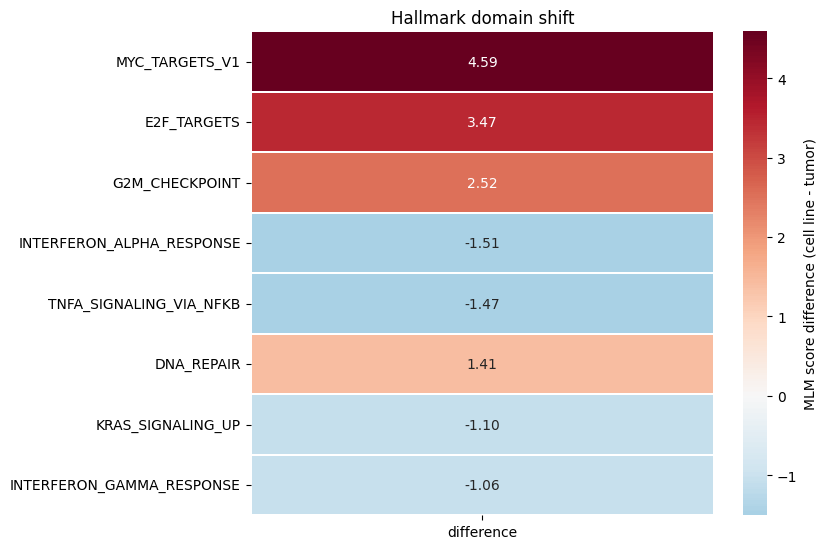

In [9]:
plots.plot_domain_shift(domain_shift, path=FIG_DIR / "mlm_domain_shift.png")
plt.show()

## Pathway-profile concordance

For each cell line and each tumor subpopulation, the median pathway
profiles are correlated across the 50 Hallmark terms. The primary and
runner-up boxes show how the latent candidates rank in that view.

Saved to `de_dir/hallmark_mlm/mlm_concordance.csv`. The primary/runner-up
table goes to `de_dir/hallmark_mlm/mlm_primary_runner_up.csv`.

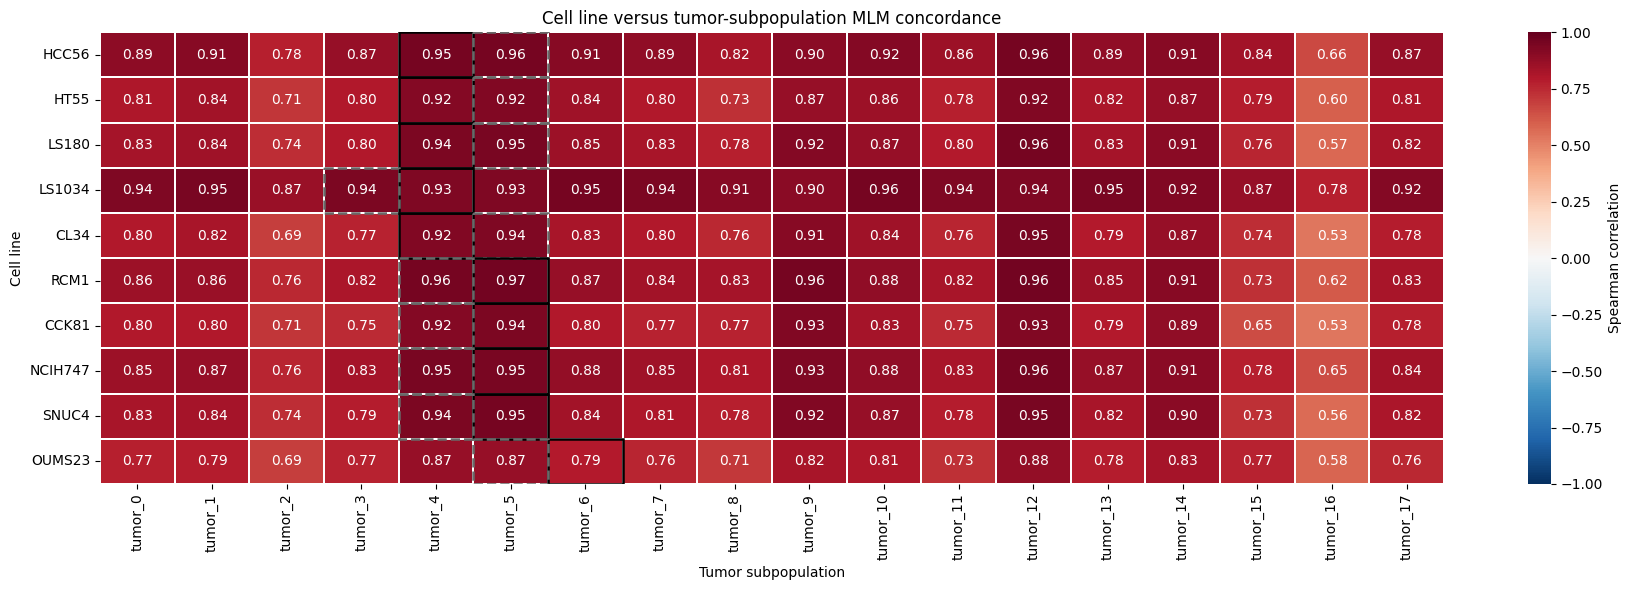

In [10]:
mlm_line_order = [str(line).replace("line_", "") for line in line_order]
mlm_matrix = mlm.concordance_matrix(
    pathway_scores, score_obs, mlm_line_order, tumor_order
)
mlm_matrix.to_csv(mlm_dir / "mlm_concordance.csv")
plots.plot_concordance(
    mlm_matrix,
    line_matches,
    FIG_DIR / "mlm_concordance.png",
    title="Cell line versus tumor-subpopulation MLM concordance",
)
plt.show()

In [11]:
runner_up = mlm.primary_runner_up(mlm_matrix, line_matches)
runner_up.to_csv(mlm_dir / "mlm_primary_runner_up.csv", index=False)
runner_up.round(3)

,cell_line,primary_match,runner_up,primary_rho,runner_up_rho,primary_minus_runner_up
0,OUMS23,tumor_6,tumor_5,0.792,0.875,-0.083
1,LS1034,tumor_4,tumor_3,0.931,0.944,-0.013
2,CL34,tumor_4,tumor_5,0.923,0.936,-0.013
3,LS180,tumor_4,tumor_5,0.943,0.951,-0.008
4,HT55,tumor_4,tumor_5,0.917,0.923,-0.006
5,HCC56,tumor_4,tumor_5,0.955,0.960,-0.005
6,NCIH747,tumor_5,tumor_4,0.952,0.952,-0.000
7,RCM1,tumor_5,tumor_4,0.966,0.958,0.008
8,SNUC4,tumor_5,tumor_4,0.954,0.942,0.012
9,CCK81,tumor_5,tumor_4,0.942,0.922,0.021


## MLM and GSEA direction check

The signed tumor MLM contrast and the GSEA NES are not numerically
identical. The check asks whether their directions and ranks agree.

Saved to `de_dir/hallmark_mlm/mlm_gsea_consistency.csv`.

In [12]:
comparison, directional, rho = mlm.mlm_gsea_consistency(
    pathway_scores, score_obs, results_gsea_tumor, tumor_order
)
print(f"directional agreement: {directional:.1%}; Spearman: {rho:.3f}")
comparison.to_csv(mlm_dir / "mlm_gsea_consistency.csv", index=False)
comparison.head(5).round(3)

directional agreement: 68.3%; Spearman: 0.496


,subpopulation,pathway,source_median_mlm,rest_median_mlm,mlm_delta,nes,fdr_qval,same_direction
0,tumor_0,ADIPOGENESIS,0.921,0.641,0.281,-0.686,0.909,False
1,tumor_0,ALLOGRAFT_REJECTION,1.206,1.177,0.029,-2.002,0.000,False
2,tumor_0,ANDROGEN_RESPONSE,2.391,2.306,0.084,1.536,0.106,True
3,tumor_0,ANGIOGENESIS,-0.640,-0.597,-0.043,-1.272,0.281,True
4,tumor_0,APICAL_JUNCTION,0.365,0.361,0.004,-1.004,0.617,False


## Tumor-centered and z-space pathway similarity

Centering or standardizing group medians by the tumor reference removes the
baseline epithelial pathway scale so subpopulation-specific differences stand
out clearly.

The similarity and null tables stay in memory. Only the figure is written
under `figures/BIOVAL/`.

In [13]:
rank_readouts, rank_summary, null_summary, similarity_by_method, pathway_sets = (
    mlm.pathway_similarity_evaluation(
        pathway_scores,
        score_obs,
        results_gsea_tumor,
        line_matches,
        mlm_line_order,
        tumor_order,
        n_perm=1000,
        seed=SEED,
    )
)
for name, cols in pathway_sets.items():
    print(f"{name}: {len(cols)} pathways")
display(rank_summary.round(3))
display(null_summary.round(3))

all50: 50 pathways
tumor_sig: 39 pathways
tumor_sig_noprolif: 35 pathways


,n_lines,median_primary_rank,primary_top1_rate,primary_top3_rate,median_runner_up_rank
method,,,,,
centered_spearman | tumor_sig,10,1.0,0.6,0.8,2.0
centered_spearman | all50,10,1.5,0.5,0.8,2.0
z_dist | tumor_sig,10,1.5,0.5,0.8,2.0
centered_spearman | tumor_sig_noprolif,10,2.0,0.4,0.8,2.0
z_dist | tumor_sig_noprolif,10,2.0,0.4,0.7,2.0
z_dist | all50,10,2.0,0.4,0.8,1.5
uncentered_spearman | all50 (baseline),10,3.0,0.3,0.8,2.0


,method,observed_median_rank,null_median_rank_mean,null_median_rank_q05,observed_top1_rate,null_top1_rate,observed_top3_rate,null_top3_rate,p_median_rank
4,centered_spearman | tumor_sig,1.0,9.404,5.000,0.6,0.056,0.8,0.165,0.000
3,z_dist | tumor_sig,1.5,9.503,5.500,0.5,0.056,0.8,0.166,0.001
2,centered_spearman | all50,1.5,9.428,5.500,0.5,0.056,0.8,0.164,0.001
1,z_dist | all50,2.0,9.474,5.500,0.4,0.056,0.8,0.170,0.000
6,centered_spearman | tumor_sig_noprolif,2.0,9.464,5.500,0.4,0.056,0.8,0.171,0.000
5,z_dist | tumor_sig_noprolif,2.0,9.570,5.475,0.4,0.056,0.7,0.165,0.000
0,uncentered_spearman | all50 (baseline),3.0,9.547,5.500,0.3,0.056,0.8,0.169,0.002


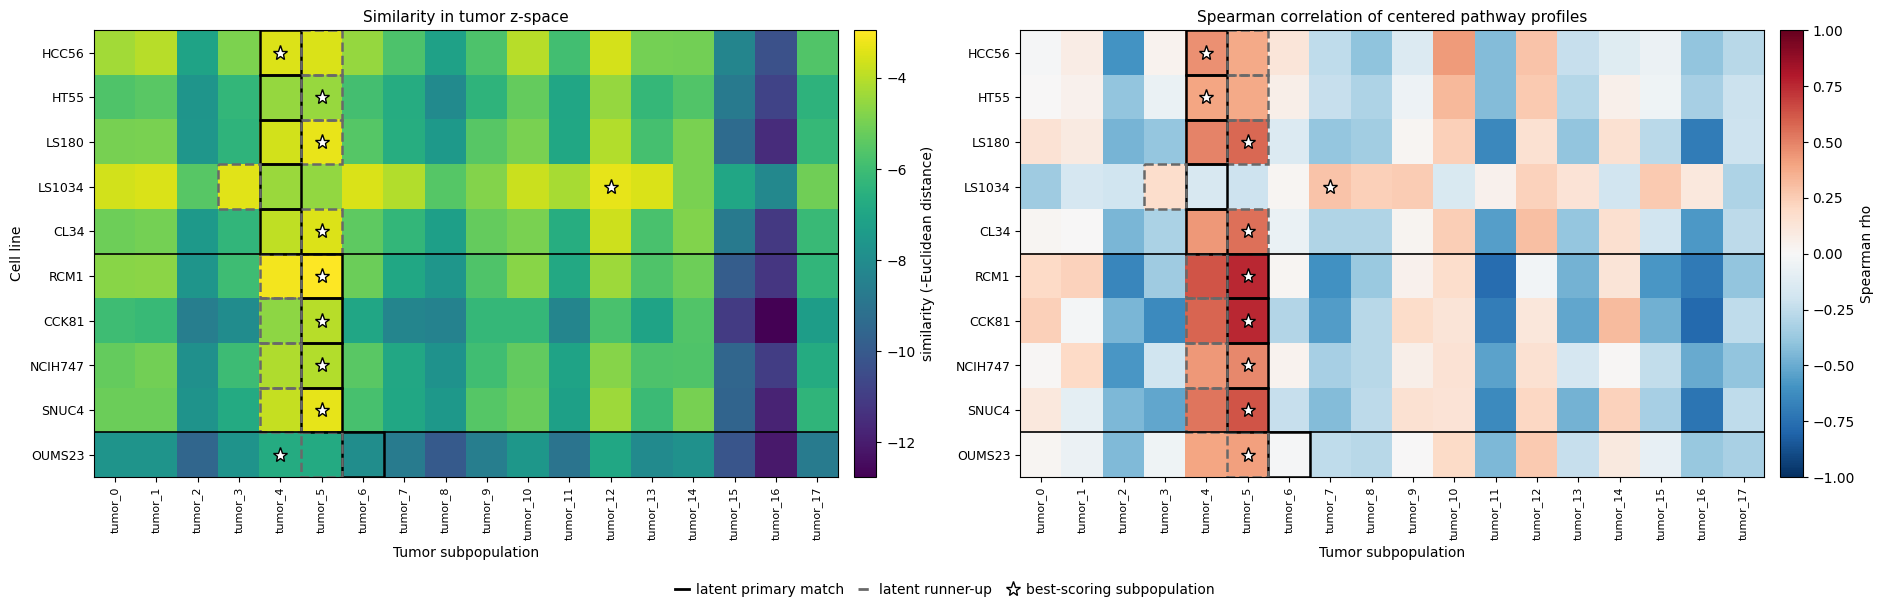

In [14]:
plots.plot_pathway_similarity(
    similarity_by_method,
    line_matches,
    mlm_line_order,
    tumor_order,
    path=FIG_DIR / "pathway_profile_similarity.png",
)
plt.show()

# Combined summary

The table combines the latent candidate, the signature rank, and the MLM
primary-minus-runner-up difference. It is a descriptive summary, not a
verdict rule.

Saved to `de_dir/candidate_summary.csv`.

In [15]:
summary = line_matches[
    [
        "n_cells",
        "primary_match",
        "primary_frac",
        "second_match",
        "margin",
        "median_dist_nearest_tumor",
        "low_proximity",
    ]
].copy()
signature_rank = signature_readout.set_index("cell_line")["all Hallmark: primary rank"]
summary["signature_primary_rank"] = [
    int(signature_rank.loc[str(line).replace("line_", "")]) for line in summary.index
]
summary["mlm_primary_rho"] = [
    float(mlm_matrix.loc[str(line).replace("line_", ""), summary.loc[line, "primary_match"]])
    for line in summary.index
]
summary["mlm_runner_up_rho"] = [
    float(mlm_matrix.loc[str(line).replace("line_", ""), summary.loc[line, "second_match"]])
    for line in summary.index
]
summary["mlm_primary_minus_runner_up"] = (
    summary["mlm_primary_rho"] - summary["mlm_runner_up_rho"]
)
summary.to_csv(de_dir / "candidate_summary.csv")
summary.round(3)

,n_cells,primary_match,primary_frac,second_match,margin,median_dist_nearest_tumor,low_proximity,signature_primary_rank,mlm_primary_rho,mlm_runner_up_rho,mlm_primary_minus_runner_up
cell_line,,,,,,,,,,,
HCC56,102,tumor_4,0.422,tumor_5,0.279,1.335,False,1,0.955,0.960,-0.005
HT55,211,tumor_4,0.517,tumor_5,0.216,1.371,False,1,0.917,0.923,-0.006
LS180,362,tumor_4,0.412,tumor_5,0.143,1.112,False,2,0.943,0.951,-0.008
LS1034,153,tumor_4,0.267,tumor_3,0.073,1.124,False,1,0.931,0.944,-0.013
CL34,418,tumor_4,0.441,tumor_5,0.027,1.047,False,1,0.923,0.936,-0.013
RCM1,131,tumor_5,0.537,tumor_4,0.297,1.219,False,1,0.966,0.958,0.008
CCK81,127,tumor_5,0.517,tumor_4,0.264,1.002,False,1,0.942,0.922,0.021
NCIH747,80,tumor_5,0.466,tumor_4,0.132,1.140,False,1,0.952,0.952,-0.000
SNUC4,471,tumor_5,0.418,tumor_4,0.019,0.983,False,2,0.954,0.942,0.012
